In [1]:
import sys
import os
import numpy as np
from matplotlib import pyplot as plt
import pickle
import wandb

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils

In [2]:
import importlib
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/sweep/../../../../utils/plot_utils.py'>

In [3]:
api = wandb.Api()
username = 'julian-zim-uni-vie'

In [4]:
projects = {
	'll00': {
		'bom' : [
			'FLY bom-ll00 26.01 14h22 0 2019_07_01_fly2',
			'FLY bom-ll00 26.01 20h56 1 2019_08_14_fly1',
			'FLY bom-ll00 27.01 11h23 2 2019_08_14_fly2',
			'FLY bom-ll00 27.01 21h06 5 2019_08_20_fly3',
			'FLY bom-ll00 28.01 08h24 6 2019_10_02_fly2',
		],
		'hgm' : [
			'FLY hgm-ll00 26.01 14h31 0 2019_07_01_fly2',
			'FLY hgm-ll00 27.01 09h45 1 2019_08_14_fly1',
		],
		'bom_rs' : [
			'FLY bom_rs-ll00 26.01 14h28 0 2019_07_01_fly2',
			'FLY bom_rs-ll00 27.01 07h47 1 2019_08_14_fly1',
		],
		'hgm_rs' : [
			'FLY hgm_rs-ll00 26.01 14h35 0 2019_07_01_fly2',
		],
	},
}

In [5]:
hyperparams = {
	ll: {
		model : {
			'means': {
				**(
					{'vb_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.endswith('rs') else {}
				),
				'wb_reg_lambda': {
					'linear': -1.,
					'geometric': -1.,
				},
				**(
					{'wm_reg_lambda': {
						'linear': -1.,
						'geometric': -1.,
					}} if model.startswith('hgm') else {}
				),
			},
			'datasets': {
				dataset: {
					'mpe_loss': {
						'all': np.empty(shape=()),
					},
					**(
						{'vb_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.endswith('rs') else {}
					),
					'wb_reg_lambda': {
						'all': np.empty(shape=()),
						'mean': {
							'linear': -1.,
							'geometric': -1.,
						},
					},
					**(
						{'wm_reg_lambda': {
							'all': np.empty(shape=()),
							'mean': {
								'linear': -1.,
								'geometric': -1.,
							},
						}} if model.startswith('hgm') else {}
					),
				} for dataset in [' '.join(project.split(' ')[-2:]) for project in projects[ll][model]]
			},
		} for model in projects[ll].keys()
	} for ll in projects.keys()
}

In [6]:
percentile = 5

for ll in hyperparams.keys():
	for model in hyperparams[ll].keys():
		for dataset in hyperparams[ll][model]['datasets']:
			project = [name for name in projects[ll][model] if name.endswith(dataset)][0]

			print(f'getting runs for {project}...')
			runs = api.runs(f'{username}/{project}')

			print('sorting them...')
			sorted_runs = sorted(runs, key=lambda run: run.summary.get('mpe_loss', float('inf')))

			print(f'processing mpe losses...')
			mpe_losses = np.array([run.summary.get('mpe_loss', float('inf')) for run in sorted_runs])
			hyperparams[ll][model]['datasets'][dataset]['mpe_loss']['all'] = mpe_losses

			if model.endswith('rs'):
				print(f'processing vb_reg_lambdas...')
				vb_reg_lambdas = np.array([run.config['vb_reg_lambda'] for run in sorted_runs])
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['all'] = vb_reg_lambdas
				best_vb_reg_lambdas = vb_reg_lambdas[:int(percentile / 100 * len(vb_reg_lambdas))]
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['linear'] = np.mean(best_vb_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['vb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_vb_reg_lambdas)))

			print(f'processing wb_reg_lambdas...')
			wb_reg_lambdas = np.array([run.config['wb_reg_lambda'] for run in sorted_runs])
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['all'] = wb_reg_lambdas
			best_wb_reg_lambdas = wb_reg_lambdas[:int(percentile / 100 * len(wb_reg_lambdas))]
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['linear'] = np.mean(best_wb_reg_lambdas)
			hyperparams[ll][model]['datasets'][dataset]['wb_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wb_reg_lambdas)))

			if model.startswith('hgm'):
				print(f'processing wm_reg_lambdas...')
				wm_reg_lambdas = np.array([run.config['wm_reg_lambda'] for run in sorted_runs])
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['all'] = wm_reg_lambdas
				best_wm_reg_lambdas = wm_reg_lambdas[:int(percentile / 100 * len(wm_reg_lambdas))]
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['linear'] = np.mean(best_wm_reg_lambdas)
				hyperparams[ll][model]['datasets'][dataset]['wm_reg_lambda']['mean']['geometric'] = np.power(10, np.mean(np.log10(best_wm_reg_lambdas)))

		print('averaging across projects...')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			for mean_type in hyperparams[ll][model]['means'][hyperparam].keys():

				hyperparam_mean = np.mean(np.array([
					hyperparams[ll][model]['datasets'][dataset][hyperparam]['mean'][mean_type] for dataset in hyperparams[ll][model]['datasets'].keys()
				]))
				hyperparams[ll][model]['means'][hyperparam][mean_type] = hyperparam_mean

getting runs for FLY bom-ll00 26.01 14h22 0 2019_07_01_fly2...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for FLY bom-ll00 26.01 20h56 1 2019_08_14_fly1...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for FLY bom-ll00 27.01 11h23 2 2019_08_14_fly2...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for FLY bom-ll00 27.01 21h06 5 2019_08_20_fly3...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
getting runs for FLY bom-ll00 28.01 08h24 6 2019_10_02_fly2...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
averaging across projects...
getting runs for FLY hgm-ll00 26.01 14h31 0 2019_07_01_fly2...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
processing wm_reg_lambdas...
getting runs for FLY hgm-ll00 27.01 09h45 1 2019_08_14_fly1...
sorting them...
processing mpe losses...
processing wb_reg_lambdas...
processing 

In [7]:
with open('./hyperparams.pkl', 'wb') as file:
    pickle.dump(hyperparams, file)

In [8]:
with open('./hyperparams.pkl', 'rb') as file:
    hyperparams = pickle.load(file)

In [9]:
for ll in hyperparams.keys():
	print(f'{ll}')
	for model in hyperparams[ll].keys():
		print(f'\t{model}')
		for hyperparam in hyperparams[ll][model]['means'].keys():
			print(f'\t\t{hyperparam}')
			for mean_type in hyperparams[ll][model]['means'][hyperparam].keys():
				_mean = hyperparams[ll][model]['means'][hyperparam][mean_type]
				print(f'\t\t\t{mean_type}: \t{_mean}')

ll00
	bom
		wb_reg_lambda
			linear: 	0.3981745001276231
			geometric: 	0.3418975624828982
	hgm
		wb_reg_lambda
			linear: 	0.3869460455676905
			geometric: 	0.36916766413672286
		wm_reg_lambda
			linear: 	0.01611279875966478
			geometric: 	0.002825577750168944
	bom_rs
		vb_reg_lambda
			linear: 	0.17162594875596113
			geometric: 	0.06468715415391019
		wb_reg_lambda
			linear: 	0.20865519956031936
			geometric: 	0.0926218965576124
	hgm_rs
		vb_reg_lambda
			linear: 	0.40841855249560916
			geometric: 	0.05516473637640719
		wb_reg_lambda
			linear: 	0.0002638785945517429
			geometric: 	1.343087934084235e-06
		wm_reg_lambda
			linear: 	1.7441575781290727e-07
			geometric: 	1.553981789776757e-08


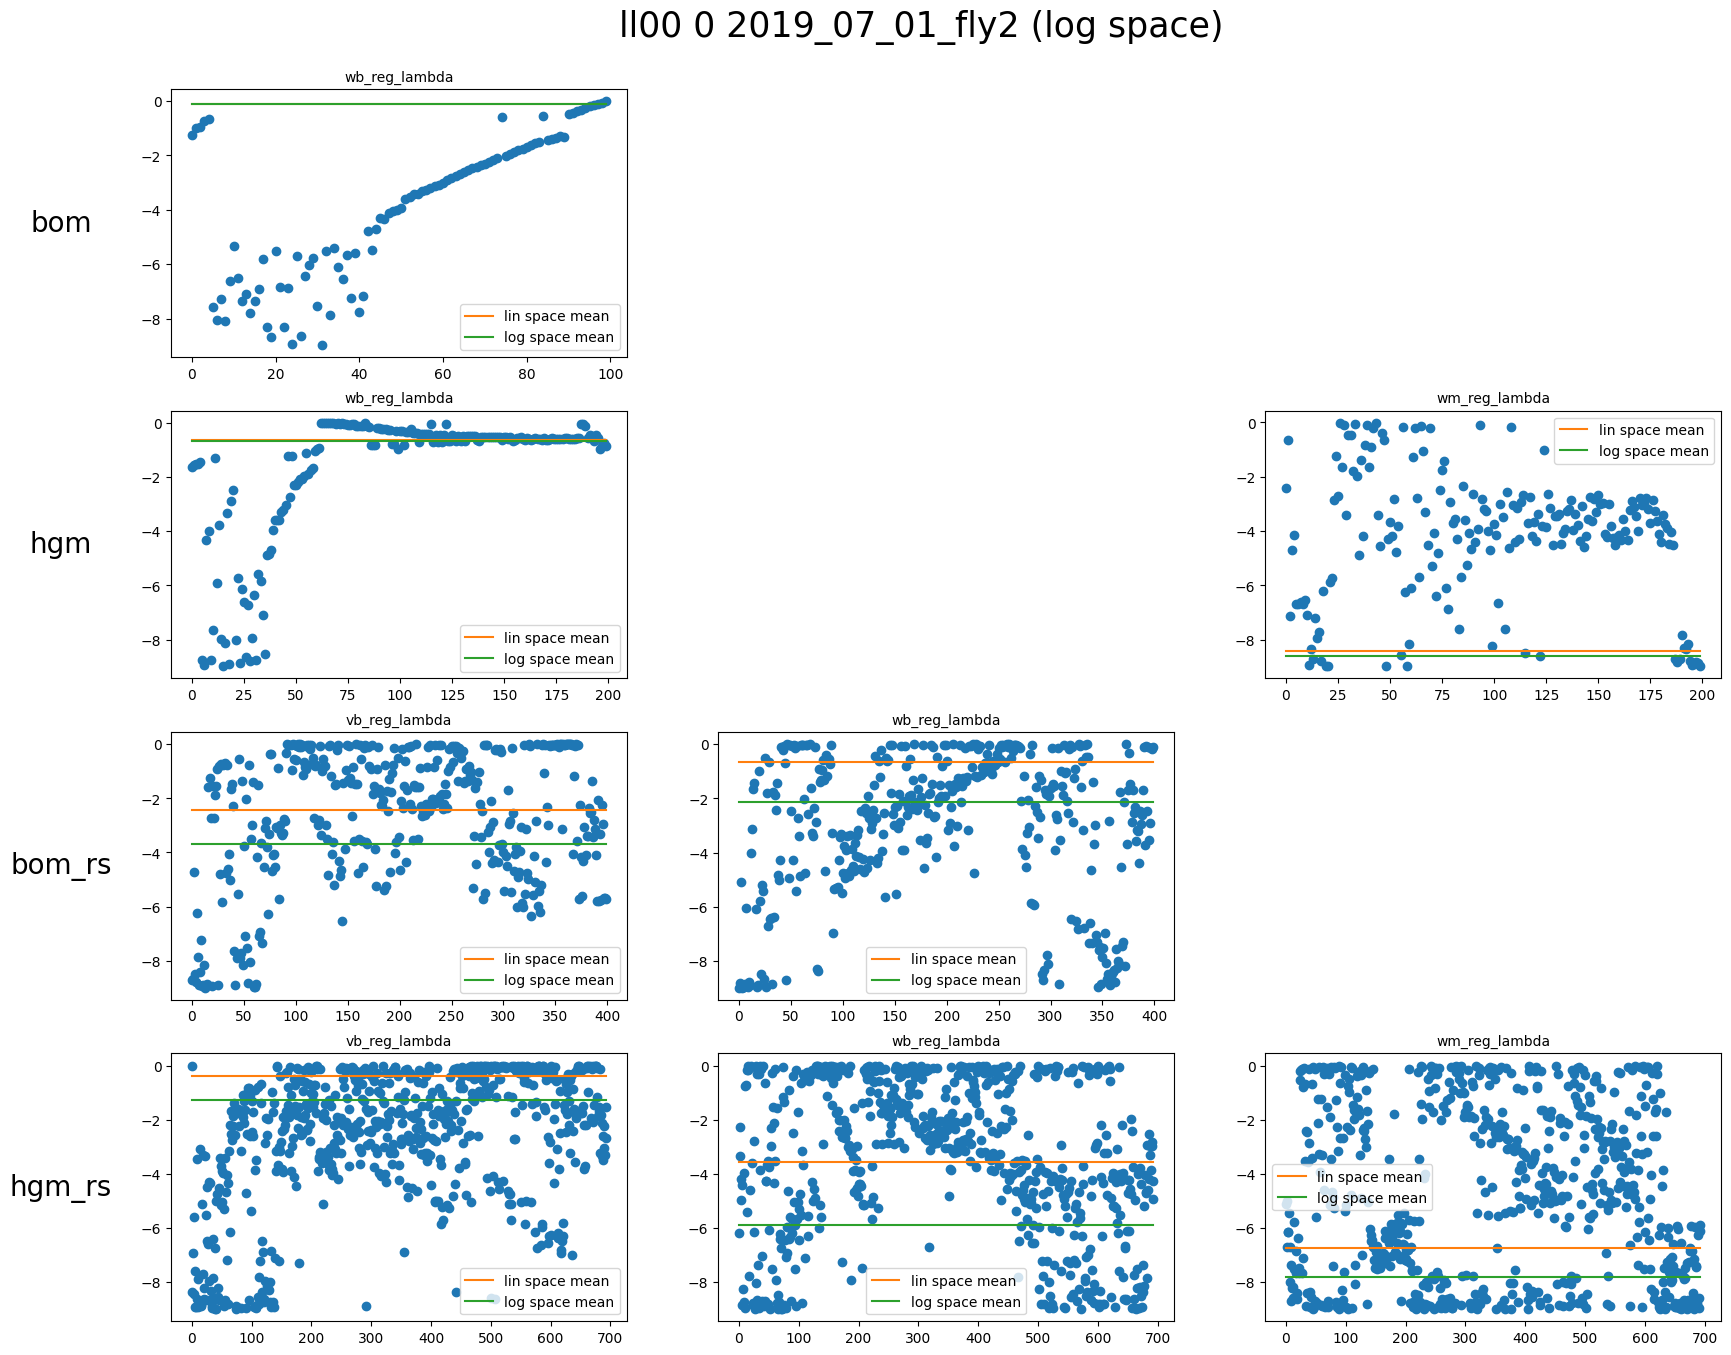

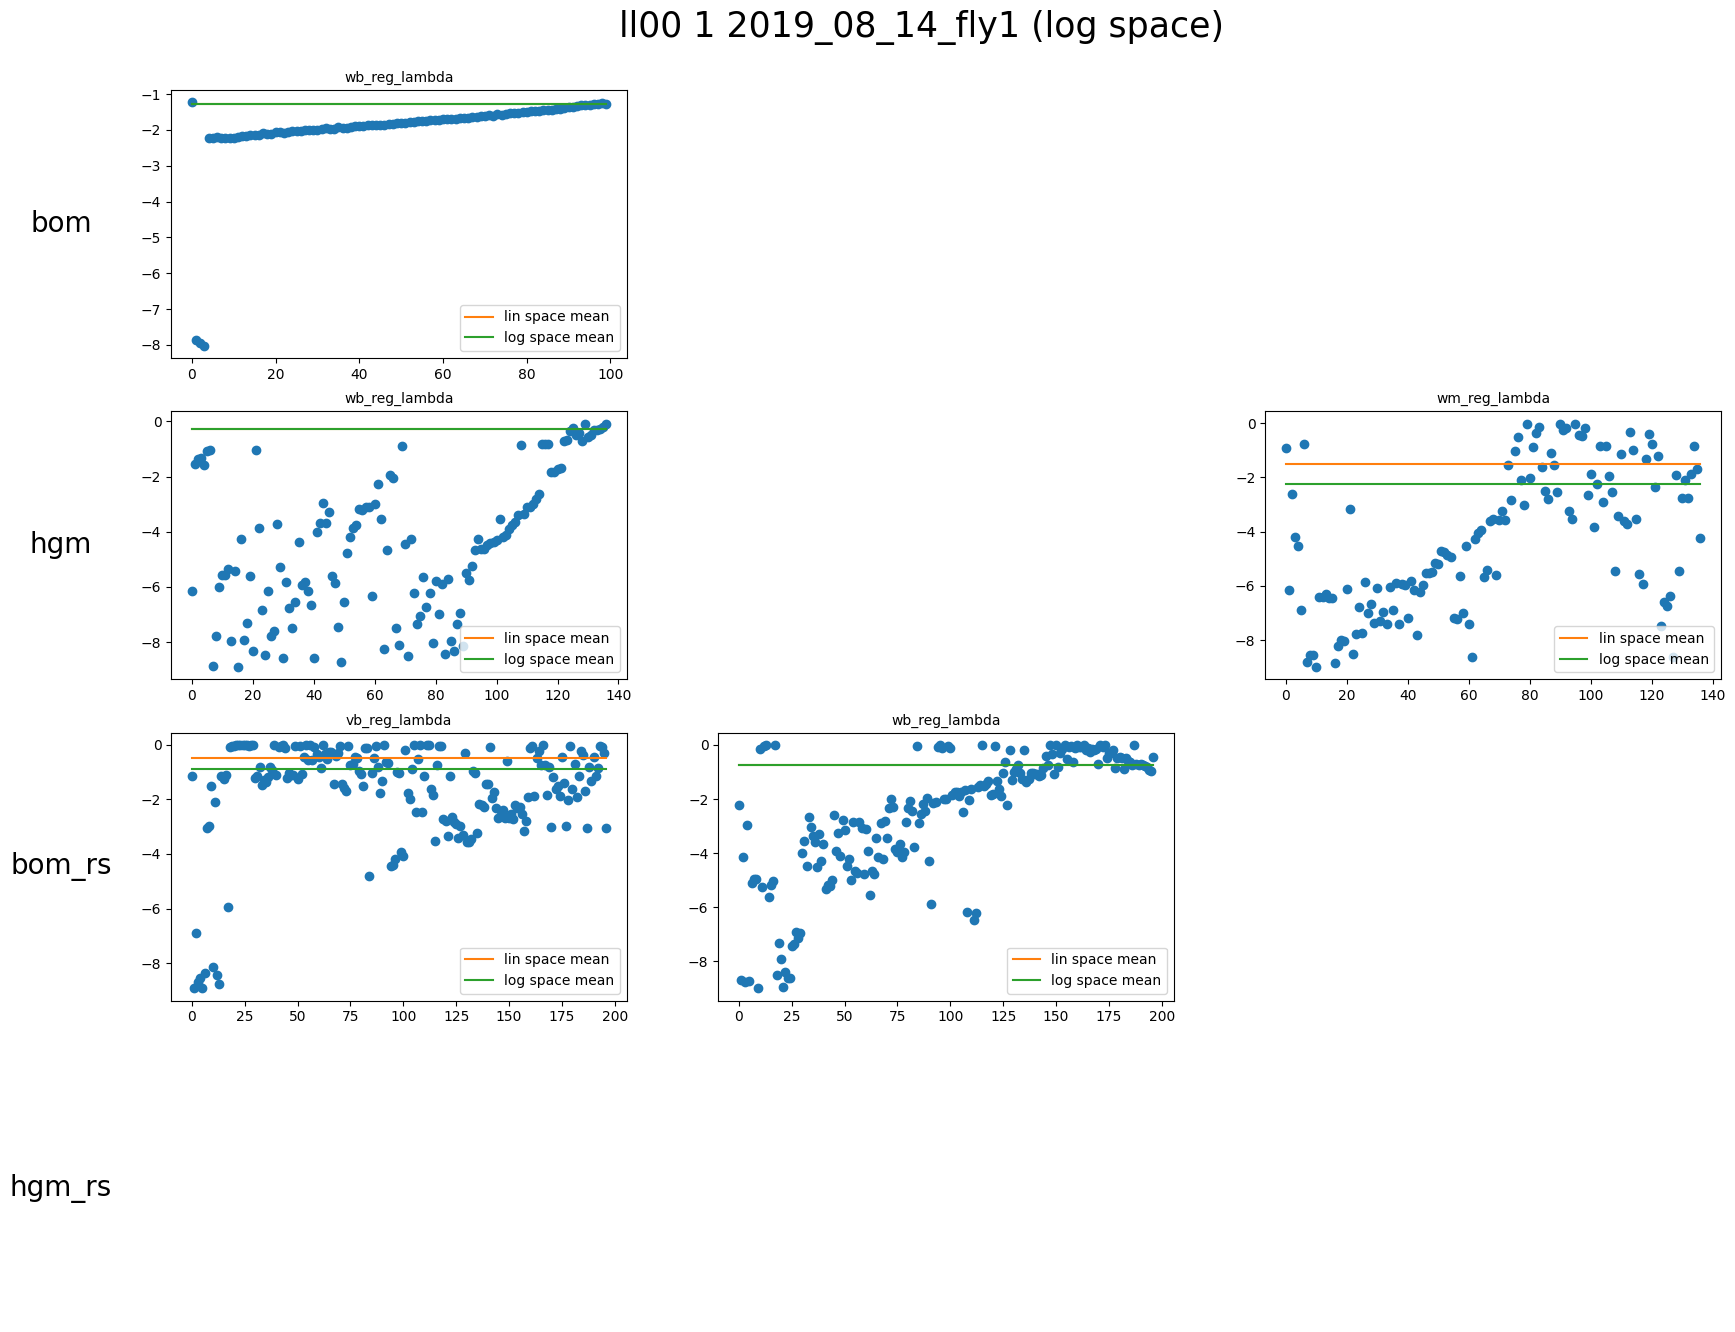

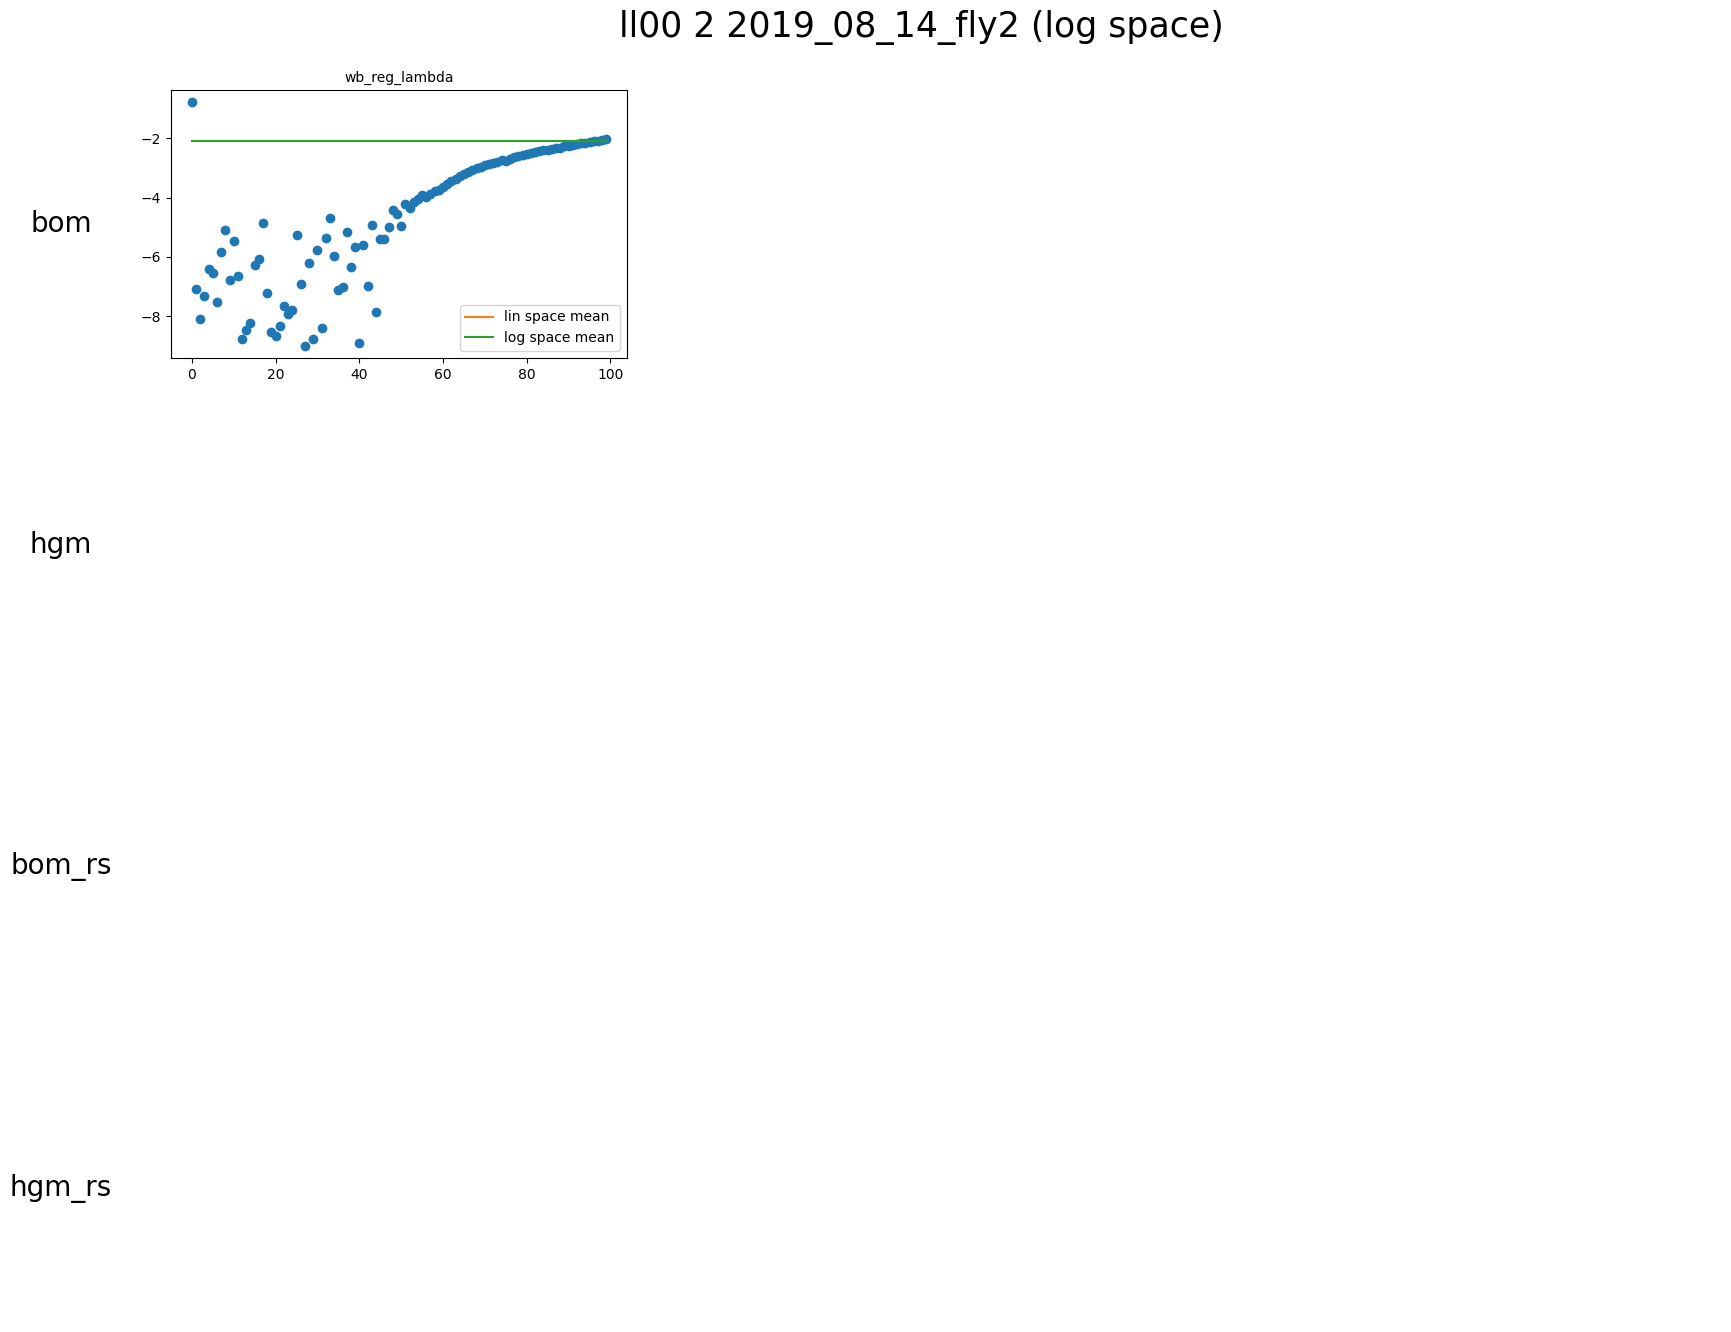

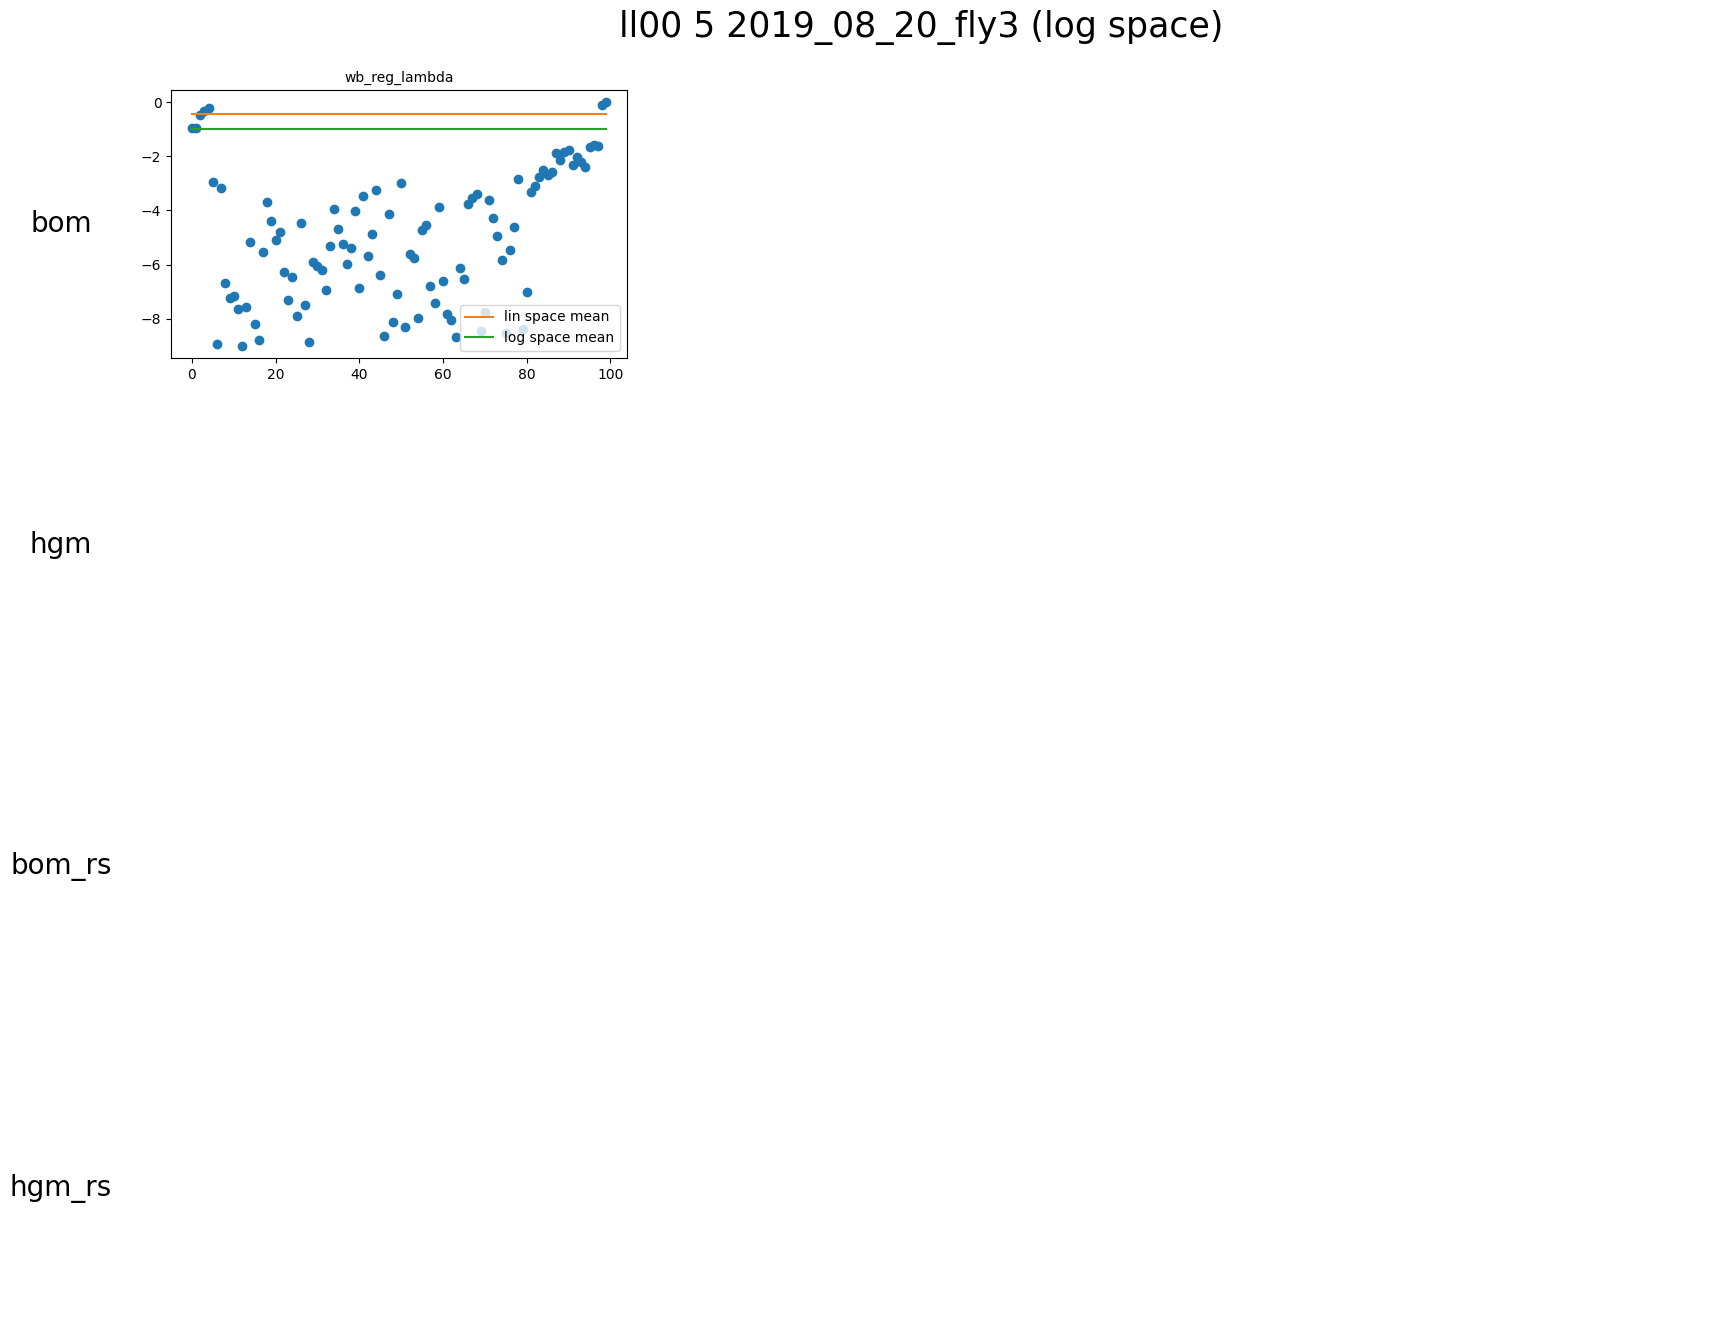

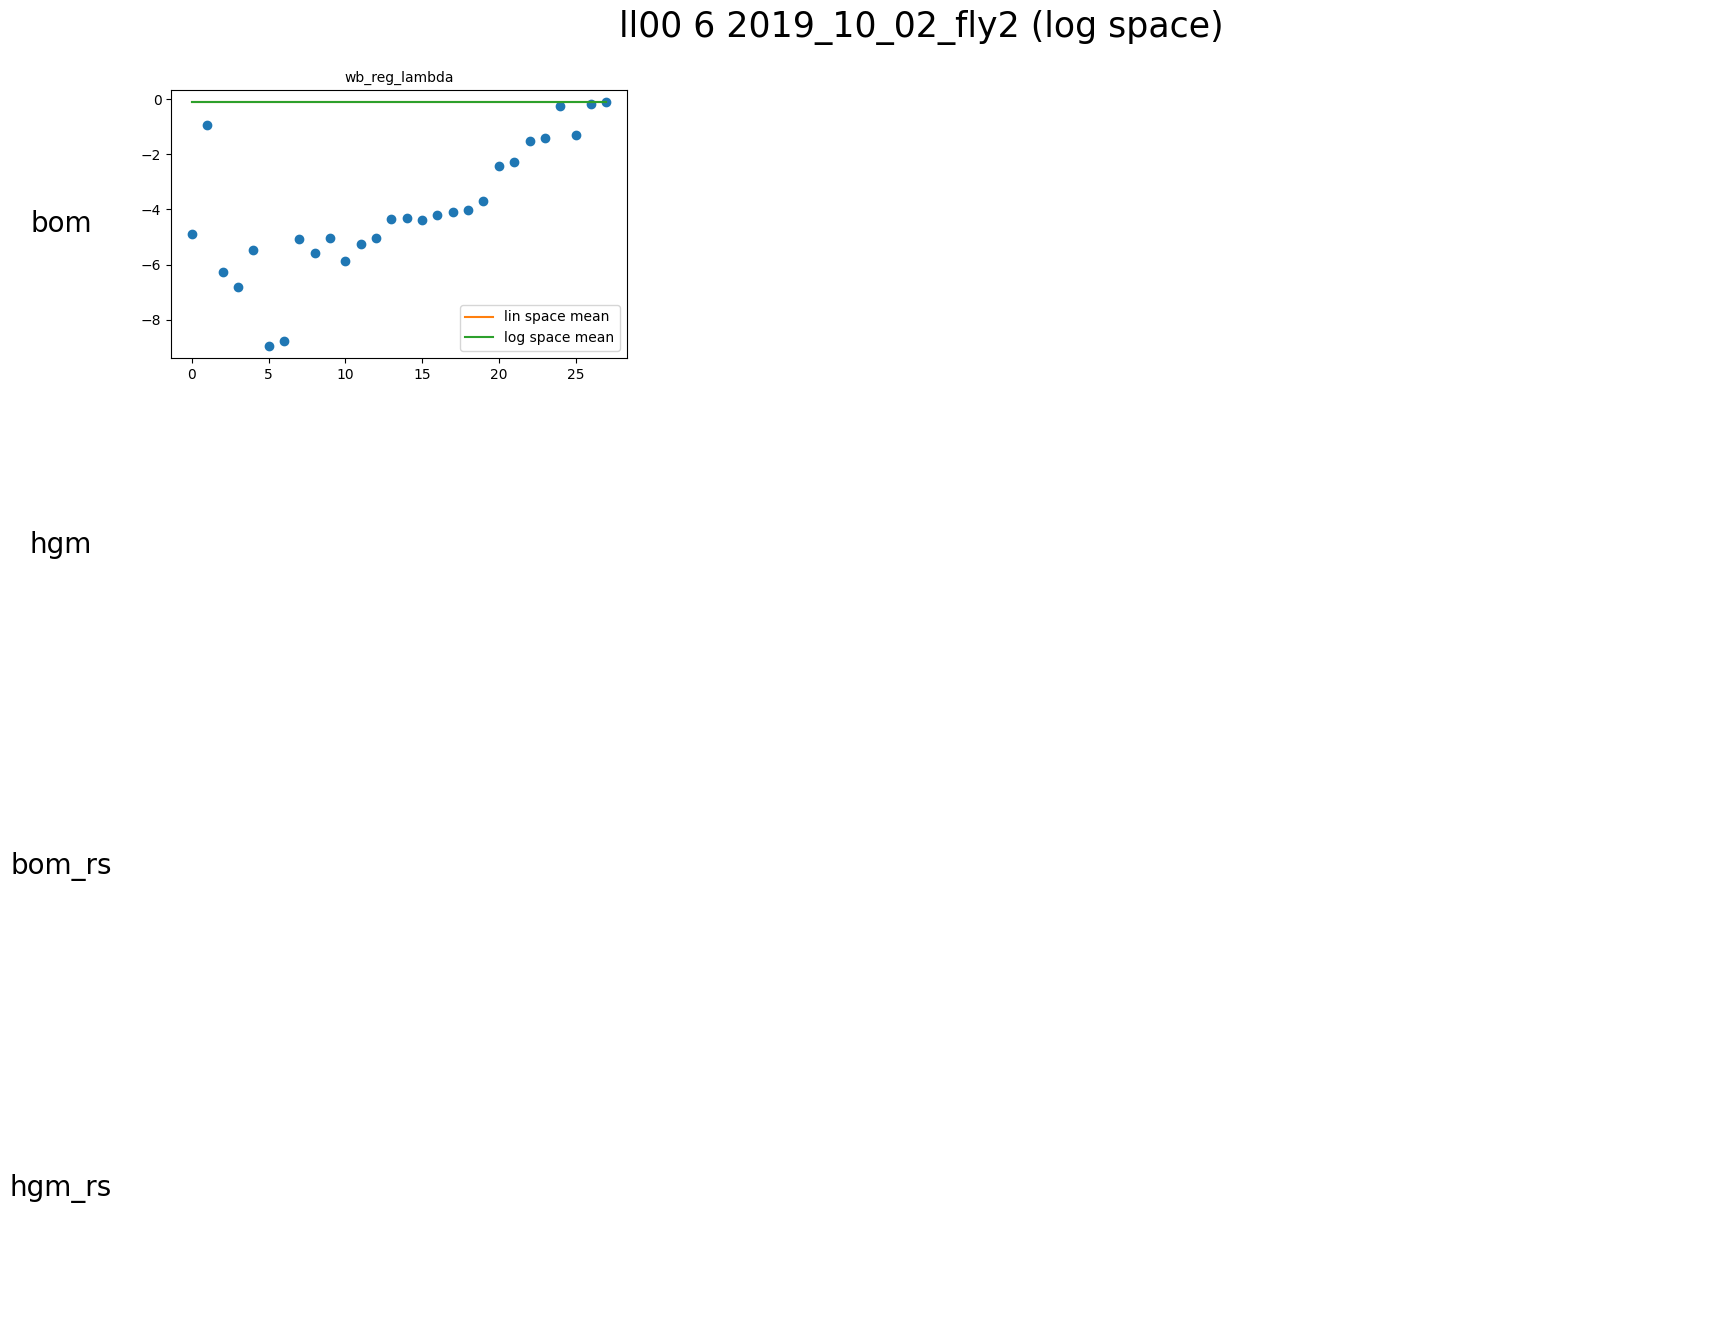

In [10]:
save = False
plot_utils.plot_hyperparams(hyperparams, None,
							ll='ll00', histograms=False, space='logarithmic',
							save_dirpath='../../out/plots/hyperparameters' if save else None)